<a href="https://colab.research.google.com/github/fadilaha/Ising-Model-on-Social-Opinion-Dynamic/blob/main/Experiment_T_HeatBath_AB_BC_Residual.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#__Heat-Bath Dynamics with A-B Model Transition Rules and Blume-Capel Resistance Model__

This model has updated the rules of spin transition, adopting the A-B Model-inspired rules.  
__Transition Rules__  
*   +1 -> {+1, 0}; +1 can maintains its state or moves to 0  
*   0 -> {+1, 0, -1}; 0 can maintains its state or moves to +1 and -1  
*   -1 -> {0, -1}; -1 can maintains its state or moves to 0
*   Both +1 and -1 need to pass through 0 state first before transitioning to its opposites.  
In this logic, +1 and -1 can choose 0, and later:
1. Maintain its 0 state
2. Move to its opposite
3. Go back to its initial state  
The decision depends on the randomly drawn state by the system, based on the calculated probabilities for each possible states  

__The Probabilities__  

Just like the previous Heat-Bath Dynamics, for each selected spin, the probabilities of the three possible states are calculated based on their corresponding energies E($s'_i$) under the current effective field.  

$h_{eff}$ =  $h + JqM$  

$E(s'_i)$ = $-s'_i$($h_{eff}$) + $Ds'^2_i$  
where,  
$s'_i$ : possible new states of chosen spin  
$D$ : resistance parameter. It has negative value shows tendencies to maintain its non-neutral state.  

Boltzmann weight, $w($s'_i$) = e^{\frac{-E(s'_i)}{kB.T}}$  

Probability of a new state, $P($s'_i$) = {\frac{e^{\frac{-E(s'_i)}{kB.T}}}{(\sum_{s'_i} {w(s'_i)}}}$ ; $s'_i$ = {possible new state of the current chosen spin}

The system will draw a new state by randomly choose one element from possible_states. However, each element's chance of being chosen equal to the corresponding value in the previously calculated probabilities.  

__State-dependent neutrality (Blume-Capel D)__  

$E(s'_i)$ = $-s'_i$($h_{eff}$) + $Ds'^2_i$  

In this model, $D$ is always negative (resistance to leaving +1/-1) and its size depends on the collective opinion.

With $D_{0}$ = $D_{initial}$ (negative) and $dM$ = the distance of $|M|$ from the threshold of its band:

| Condition | dM | D |
|---|---|---|
| \|M\| < 0.5 | – | D0 |
| 0.5 ≤ \|M\| ≤ 0.6 | \|M\| − 0.5 | D0·(1 + k·dM) |
| \|M\| > 0.6 | \|M\| − 0.6 | −exp(\|D0\| + dM) |

\begin{cases} D_0= -0.5, & |M| < 0.5 \\ D_0\,(1 + dM), & 0.5 \le |M| \le 0.6 \\ -e^{\left(|D_0| + |dM|\right)}, & 0.6 < |M| \end{cases}

The further the majority is past its threshold, the stronger the resistance (D more negative). When the majority weakens (|M| falls), dM shrinks and the resistance weakens. Positive and negative majorities are treated the same because the rule uses |M|.

D is computed once at the start of each Monte Carlo step from M at the end of the previous step, and held fixed during that step.


In [55]:
#External Event Generator
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
# 1. PARAMETERS YOU CAN ADJUST
total_days = 250          # Total simulation period
appearance_interval = 10   # New event every 7 days
first_event_day = 5       # Day of the first event
fade_days = 10            # Influence fades until this event age
seed = 58                 # Change seed to randomize again

# Random field settings
min_amplitude = 0.1
max_amplitude = 0.5

# Probability of each field direction
p_positive = 0.4
p_negative = 0.4
p_neutral = 0.2

# 2. GENERATE EVENT APPEARANCE DAYS
appearance_days = np.arange(first_event_day, total_days, appearance_interval)

# 3. RANDOMIZE FIELD VALUES
rng = np.random.default_rng(seed)

# Random maximum amplitude for each event
amplitudes = rng.uniform(min_amplitude, max_amplitude, len(appearance_days))

# Randomly choose positive, negative, or neutral
directions = rng.choice([1, -1, 0], size=len(appearance_days), p=[p_positive, p_negative, p_neutral])

field_values = amplitudes * directions

# 4. SAVE RAW EVENT DATA
# Columns: appearance day, field value, fade day
events = np.column_stack((appearance_days, field_values, np.full(len(appearance_days), fade_days)))

np.save("raw_external_field58.npy", events)

print("Appearance day | Field value | Fade day")
print("----------------------------------------")
for day, value, fade in events:
    print(f"{day:14.0f} | {value:11.3f} | {fade:8.0f}")

#files.download("raw_external_field58.npy")

Appearance day | Field value | Fade day
----------------------------------------
             5 |       0.000 |       10
            15 |       0.452 |       10
            25 |      -0.197 |       10
            35 |       0.183 |       10
            45 |       0.438 |       10
            55 |       0.156 |       10
            65 |       0.222 |       10
            75 |       0.155 |       10
            85 |      -0.311 |       10
            95 |       0.000 |       10
           105 |       0.000 |       10
           115 |      -0.208 |       10
           125 |       0.480 |       10
           135 |      -0.269 |       10
           145 |      -0.204 |       10
           155 |       0.324 |       10
           165 |      -0.477 |       10
           175 |      -0.454 |       10
           185 |       0.000 |       10
           195 |      -0.183 |       10
           205 |       0.000 |       10
           215 |      -0.103 |       10
           225 |       0.000 |       10

In [56]:
import numpy as np
import matplotlib.pyplot as plt

# Load External Event Schedule Generated from the cell above
# The file can be found in the https://github.com/fadilaha/Ising-Model-on-Social-Opinion-Dynamic
external_events = np.load("raw_external_field58.npy").tolist()
print("External events:", external_events)

def compute_D(M, Do, k, M_low=0.5, M_high=0.6):
    # State-dependent Blume-Capel resistance parameter (always <= 0).
    # dM = distance of |M| from the threshold of its band
    # |M| <  M_low            : D = Do
    # M_low <= |M| <= M_high  : dM = |M| - M_low ,  D = Do * (1 + k*dM)
    # |M| >  M_high           : dM = |M| - M_high,  D = -exp(|Do| + dM)

    absM = abs(M)
    if absM < M_low:
        return Do
    elif absM <= M_high:
        dM = absM - M_low
        return Do * (1 + k * dM)
    else:
        dM = absM - M_high
        return Do * (3 + k * dM)

def absorption(age, rise=(0.20, 0.30, 0.50), peak=0.80, fade_days=10, residual=0.10):
    # Fraction of ONE raw news event that the agents feel, 'age' days after publication.
    # day 0, 1, 2      : rise values (below 50%)
    # day 3            : peak (> 50%)
    # day 3..fade_days : exponential decay from the peak down to 1% of the peak
    # after fade_days  : 0 (fully gone)
    if age < 0 or age > fade_days:
        return 0.0
    if age < len(rise):
        return rise[int(age)]
    decay = -np.log(residual) / (fade_days - len(rise))
    return peak * np.exp(-decay * (age - len(rise)))

def simulate_open_population(N_up_initial, N_down_initial, N_o, T, h, J, q, Do, k_sensitivity,
                             r_growth, steps, external_events, M_low=0.5, M_high=0.6, dt=1.0,
                             rise=(0.20, 0.30, 0.50), peak=0.80, fade_days=10, residual=0.10):
    kB = 1
    # INITIAL POPULATION
    spins = ([1] * N_up_initial + [-1] * N_down_initial + [0] * N_o)
    np.random.shuffle(spins)
    N_up = N_up_initial
    N_down = N_down_initial
    N_neutral = N_o

    # DATA STORAGE
    Data_N_up = []
    Data_N_down = []
    Data_N_neutral = []
    Data_M = []
    Data_N_total = []
    Data_h_ext = []
    Data_h_felt = []
    Data_h_eff = []
    Data_D = []
    spin_history = []

    # INITIAL DATA
    N = len(spins)
    M = (N_up - N_down) / N

    Data_N_up.append(N_up)
    Data_N_down.append(N_down)
    Data_N_neutral.append(N_neutral)
    Data_M.append(M)
    Data_N_total.append(N)
    Data_h_ext.append(h)
    Data_h_felt.append(0.0)
    Data_h_eff.append(h + J * q * M)
    Data_D.append(compute_D(M, Do, k_sensitivity, M_low, M_high))
    spin_history.append(spins.copy())

    # MAIN SIMULATION
    for step in range(1, steps + 1):

        # 1. CALCULATE TOTAL EXTERNAL FIELD
        # 1a. h_ext = the news itself (decays to 1% after fade_days) -> only for plotting
        # 1b. h_felt = what the agents FEEL: each raw event weighted by the absorption profile

        h_ext = 0.0
        h_felt = 0.0

        for event_time, event_amplitude, event_fade_days in external_events:
            age = int(round(step - event_time))
            event_fade_days = int(event_fade_days)

            # Raw external field: exponential decay
            if 0 <= age <= event_fade_days:
                news_decay = np.log(100) / event_fade_days
                h_ext += event_amplitude * np.exp(-news_decay * age)

            # Absorbed external field: residual contribution
            h_felt += 0 * event_amplitude * absorption(age, rise=rise, peak=peak, fade_days=event_fade_days, residual=residual)

        ## 2. INTRINSIC GROWTH (TURNED OFF FOR THIS RESEARCH)
        #N = len(spins)
        #M = (N_up - N_down) / N

        ## dN/dt = r*N*M
        #dNdt = r_growth * N * M            #Intrinsic growth in one monte carlo sweep depends on the latest Magnetization value
        #dN = dNdt * dt

        ## Positive M -> new positive population
        #if dN > 0:
        #    new_population = int(np.floor(dN))
        #    if new_population > 0:
        #        spins.extend([1] * new_population)
        #        N_up += new_population

        ## Negative M -> new negative population
        #elif dN < 0:
        #    new_population = int(np.floor(abs(dN)))
        #    if new_population > 0:
        #        spins.extend([-1] * new_population)
        #        N_down += new_population

        ## Update total N and M after growth
        #N = len(spins)
        #M = (N_up - N_down) / N

        # 3. STATE-DEPENDENT D FOR THIS MONTE CARLO STEP
        # D depends on how far |M| (at the end of the previous MCS) is past its band threshold
        # D is computed once here and held fixed during the whole step
        M_prev = Data_M[-1]
        D = compute_D(M_prev, Do, k_sensitivity, M_low, M_high)

        # 4. HEAT-BATH SPIN DYNAMICS
        # N random spin-update attempts = 1 MCS
        for _ in range(N):
            # Current M
            M = (N_up - N_down) / N
            # Current mean-field effective field works on an individual
            h_eff = h + h_felt + J * q * M

            # Randomly choose one individual
            i = np.random.randint(0, N)
            sigma_old = spins[i]

            # TRANSITION RULE
            # +1 -> {+1, 0}; +1 can maintains its state or moves to 0
            #  0 -> {+1, 0, -1}; 0 can maintains its state or moves to +1 and -1
            # -1 -> {0, -1}; -1 can maintains its state or moves to 0
            # Both +1 and -1 need to pass through 0 state first before transitioning to its opposites.
            # In this logic, +1 and -1 can choose 0, and later:
            # (1) maintain its 0 state, (2) move to its opposite, (3) go back to its initial state
            # The decision depends on the randomly drawn state by the system, based on the calculated probabilities for each possible states.
            if sigma_old == 1:
                possible_states = np.array([1, 0])
            elif sigma_old == 0:
                possible_states = np.array([1, 0, -1])
            elif sigma_old == -1:
                possible_states = np.array([0, -1])

            # Heat-bath probabilities for allowed states
            energies = -possible_states * h_eff + D * possible_states**2     #Blume-Capel energy: field term + neutrality term
            weights = np.exp(np.clip(-energies / (kB * T), -100, 100))   #also calculate the boltzmann weights
            probabilities = weights / np.sum(weights)   #substitute the boltzmann weights (w) here to acquire the probability for each possibilities.
                                                        #probability = w/sum of w_i ; i= each possibilities for the chosen spin

            # Draw new state, randomly choose one element from possible_states
            # Each element's chance of being chosen equal to the corresponding value in the previously calculated probabilities
            sigma_new = np.random.choice(possible_states, p=probabilities)
            # Update the new chosen state
            if sigma_new != sigma_old:
                # Remove old state
                if sigma_old == 1:
                    N_up -= 1
                elif sigma_old == -1:
                    N_down -= 1
                elif sigma_old == 0:
                    N_neutral -= 1
                # Add new state
                if sigma_new == 1:
                    N_up += 1
                elif sigma_new == -1:
                    N_down += 1
                elif sigma_new == 0:
                    N_neutral += 1
            # Update spin
            spins[i] = sigma_new

        # 5. FINAL M AFTER THIS TIMESTEP
        M = (N_up - N_down) / N

        # Udpate Final effective field after Heat-Bath dynamics
        h_eff = h + h_felt + J * q * M

        # 6. STORE DATA
        Data_N_up.append(N_up)
        Data_N_down.append(N_down)
        Data_N_neutral.append(N_neutral)
        Data_M.append(M)
        Data_N_total.append(N)
        Data_h_ext.append(h_ext)
        Data_h_felt.append(h_felt)
        Data_h_eff.append(h_eff)
        Data_D.append(D)     # D that was used during this step
        spin_history.append(spins.copy())

        # PROGRESS
        if step % 10 == 0:
            print(f"MCS {step}/{steps} selesai | N = {N}")

    return (Data_N_up, Data_N_down, Data_N_neutral, Data_M, Data_N_total,
        Data_h_ext, Data_h_eff, Data_D, external_events, spin_history,
        Data_h_felt)

External events: [[5.0, 0.0, 10.0], [15.0, 0.45193344369230837, 10.0], [25.0, -0.19723658086288476, 10.0], [35.0, 0.18336818624614365, 10.0], [45.0, 0.43832517327880816, 10.0], [55.0, 0.15622918987473955, 10.0], [65.0, 0.22213301558859602, 10.0], [75.0, 0.15539247508876627, 10.0], [85.0, -0.3106288598640721, 10.0], [95.0, 0.0, 10.0], [105.0, 0.0, 10.0], [115.0, -0.2080198029652558, 10.0], [125.0, 0.4802186059675547, 10.0], [135.0, -0.2687780375356007, 10.0], [145.0, -0.2043493318213476, 10.0], [155.0, 0.32396978294955603, 10.0], [165.0, -0.4769702910159581, 10.0], [175.0, -0.4538509156265934, 10.0], [185.0, 0.0, 10.0], [195.0, -0.1826211687673073, 10.0], [205.0, 0.0, 10.0], [215.0, -0.10345769685397865, 10.0], [225.0, 0.0, 10.0], [235.0, -0.1367117796993983, 10.0], [245.0, 0.16473698168253464, 10.0]]


In [57]:
#PARAMETER INPUT
N_up_initial = 3130
N_down_initial = 1319
N_o = 602

External_field = 0
J_coupling = 0.3
q_neighbors = 4

r_growth = 0
Temperature = 1.25
Time_steps = 300

#BLUME-CAPEL NEUTRALITY PARAMETER
#D is always negative here: resistance to leaving +1/-1
D_initial = -0.5    # baseline; Do = D_initial
k_sensitivity = 5      # middle band: Do*(1 + k*dM)
M_low = 0.5              # |M| <  M_low          -> D0
M_high = 0.6             # M_low <= |M| <= M_high -> D0*(1 + k*dM),   dM = |M| - M_low
                         # |M| > M_high           -> -exp(|D0| + dM), dM = |M| - M_high

np.random.seed(42)
#EXTERNAL EVENTS IS GENERATED ON GLAUBER'S NOTEBOOK, it has loaded in the simulation cell above

#RUN SIMULATION
results = simulate_open_population(N_up_initial, N_down_initial, N_o, Temperature, External_field, J_coupling,
    q_neighbors, D_initial, k_sensitivity, r_growth, Time_steps, external_events,
    M_low=M_low, M_high=M_high, dt=1.0)

(N_up_history, N_down_history, N_neutral_history, M_history, N_total_history,
    h_ext_history, h_eff_history, D_history, external_events, spin_history,
    h_felt_history) = results

MCS 10/300 selesai | N = 5051
MCS 20/300 selesai | N = 5051
MCS 30/300 selesai | N = 5051
MCS 40/300 selesai | N = 5051
MCS 50/300 selesai | N = 5051
MCS 60/300 selesai | N = 5051
MCS 70/300 selesai | N = 5051
MCS 80/300 selesai | N = 5051
MCS 90/300 selesai | N = 5051
MCS 100/300 selesai | N = 5051
MCS 110/300 selesai | N = 5051
MCS 120/300 selesai | N = 5051
MCS 130/300 selesai | N = 5051
MCS 140/300 selesai | N = 5051
MCS 150/300 selesai | N = 5051
MCS 160/300 selesai | N = 5051
MCS 170/300 selesai | N = 5051
MCS 180/300 selesai | N = 5051
MCS 190/300 selesai | N = 5051
MCS 200/300 selesai | N = 5051
MCS 210/300 selesai | N = 5051
MCS 220/300 selesai | N = 5051
MCS 230/300 selesai | N = 5051
MCS 240/300 selesai | N = 5051
MCS 250/300 selesai | N = 5051
MCS 260/300 selesai | N = 5051
MCS 270/300 selesai | N = 5051
MCS 280/300 selesai | N = 5051
MCS 290/300 selesai | N = 5051
MCS 300/300 selesai | N = 5051


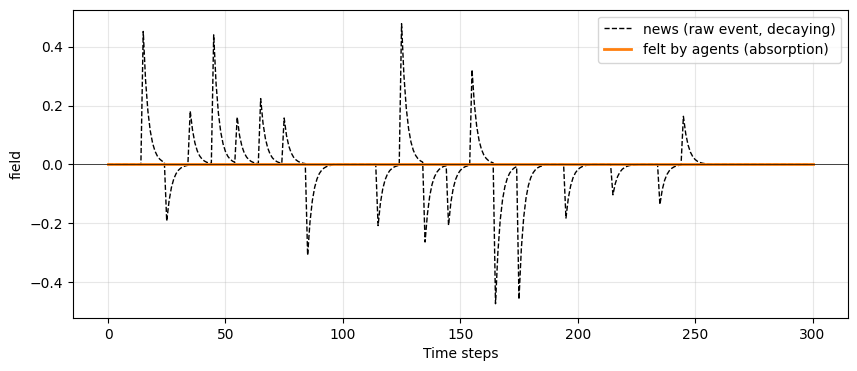

In [58]:
#Show Absorbed External Field by Agents
plt.figure(figsize=(10, 4))
plt.plot(h_ext_history,  'k--', lw=1, label='news (raw event, decaying)')
plt.plot(h_felt_history, color='tab:orange', lw=2, label='felt by agents (absorption)')
plt.axhline(0, color='k', lw=0.5)
plt.xlabel('Time steps'); plt.ylabel('field'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

__GRAPHS SECTION__

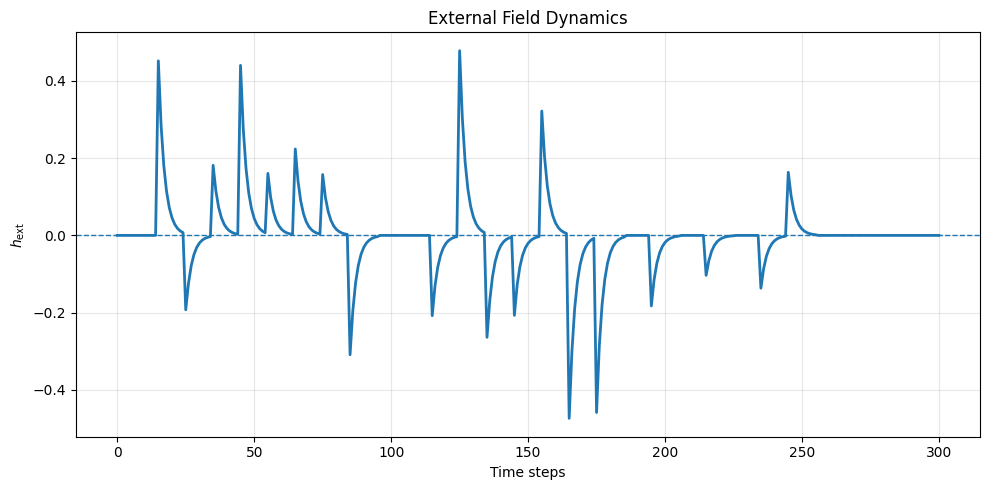

In [59]:
#PLOT EXTERNAL FIELD EVENTS
time = np.arange(len(h_ext_history))
plt.figure(figsize=(10, 5))
plt.plot(
    time,
    h_ext_history,
    linewidth=2
)
plt.axhline(
    0,
    linestyle='--',
    linewidth=1
)
plt.xlabel("Time steps")
plt.ylabel(r"$h_{\mathrm{ext}}$")
plt.title("External Field Dynamics")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

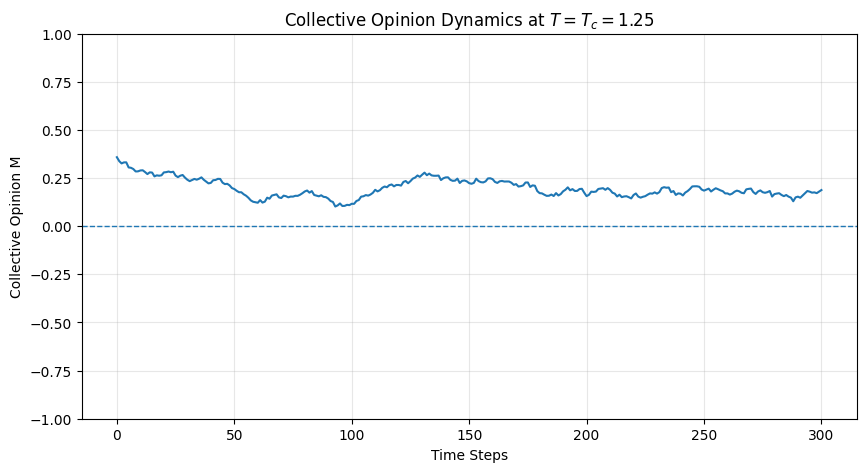

In [60]:
# PLOT COLLECTIVE OPINION (M) OVER TIME
plt.figure(figsize=(10, 5))
plt.plot(M_history)
plt.axhline(
    0,
    linestyle='--',
    linewidth=1
)
plt.xlabel("Time Steps")
plt.ylabel("Collective Opinion M")
plt.title(f"Collective Opinion Dynamics at $T=T_c={Temperature}$")
plt.ylim(-1,1)
plt.grid(alpha=0.3)
plt.show()

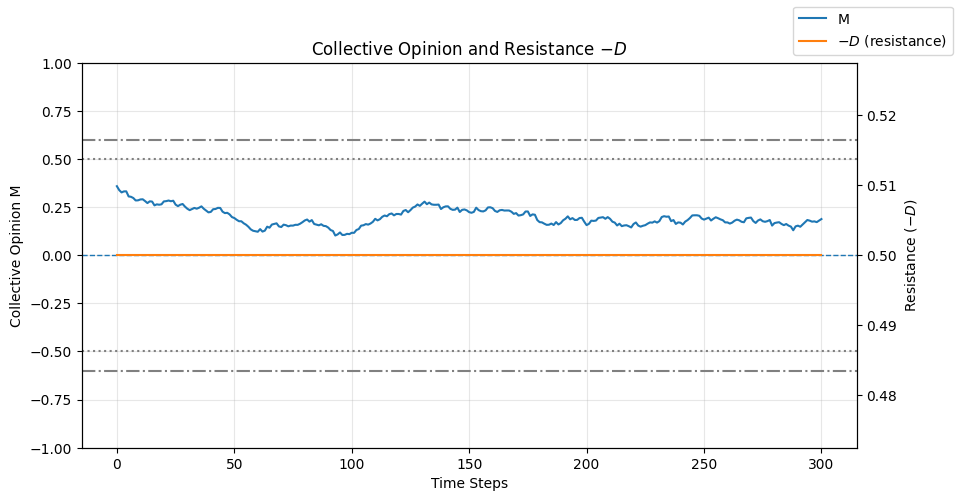

In [61]:
# PLOT M TOGETHER WITH THE ACTIVE RESISTANCE (-D)
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(M_history, label="M")
for thr in (M_low, -M_low):
    ax1.axhline(thr, linestyle=':', color='gray')
for thr in (M_high, -M_high):
    ax1.axhline(thr, linestyle='-.', color='gray')
ax1.axhline(0, linestyle='--', linewidth=1)
ax1.set_ylim(-1, 1)
ax1.set_xlabel("Time Steps")
ax1.set_ylabel("Collective Opinion M")

ax2 = ax1.twinx()
ax2.step(range(len(D_history)), -np.array(D_history), where='post',
         color='tab:orange', label=r"$-D$ (resistance)")
ax2.set_ylabel(r"Resistance $(-D)$")

fig.legend(loc="upper right")
plt.title(r"Collective Opinion and Resistance $-D$")
ax1.grid(alpha=0.3)
plt.show()

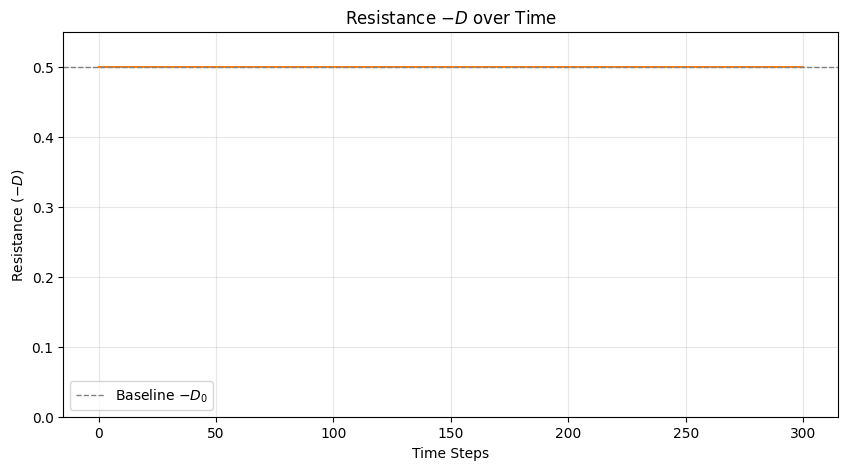

In [62]:
# PLOT ONLY THE ACTIVE RESISTANCE (-D)
minus_D = -np.array(D_history)

plt.figure(figsize=(10, 5))
plt.step(range(len(minus_D)), minus_D, where='post', color='tab:orange')
plt.axhline(-D_initial, linestyle='--', color='gray', linewidth=1,
            label=r"Baseline $-D_0$")
plt.xlabel("Time Steps")
plt.ylabel(r"Resistance $(-D)$")
plt.title(r"Resistance $-D$ over Time")
plt.ylim(0, minus_D.max() * 1.1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

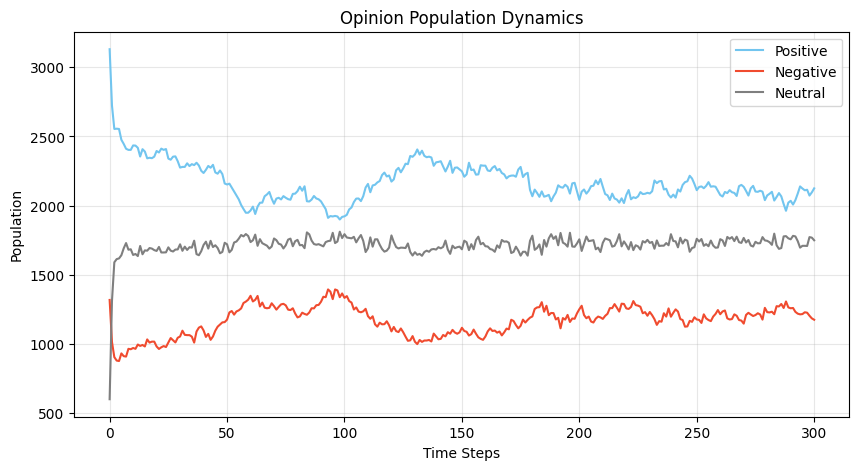

In [63]:
# PLOT OPINION POPULATION DYNAMIC OVER TIME
plt.figure(figsize=(10, 5))
plt.plot(N_up_history, color="#72C5EF", label="Positive")
plt.plot(N_down_history, color="#F04B2F", label="Negative")
plt.plot(N_neutral_history, color="#7F7F7F", label="Neutral")
plt.xlabel("Time Steps")
plt.ylabel("Population")
plt.title("Opinion Population Dynamics")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Jump up   to the locked-in branch at h + h_ext ≈ +0.089
Drop down from the locked-in branch at h + h_ext ≈ -0.099
Hysteresis width ≈ 0.188


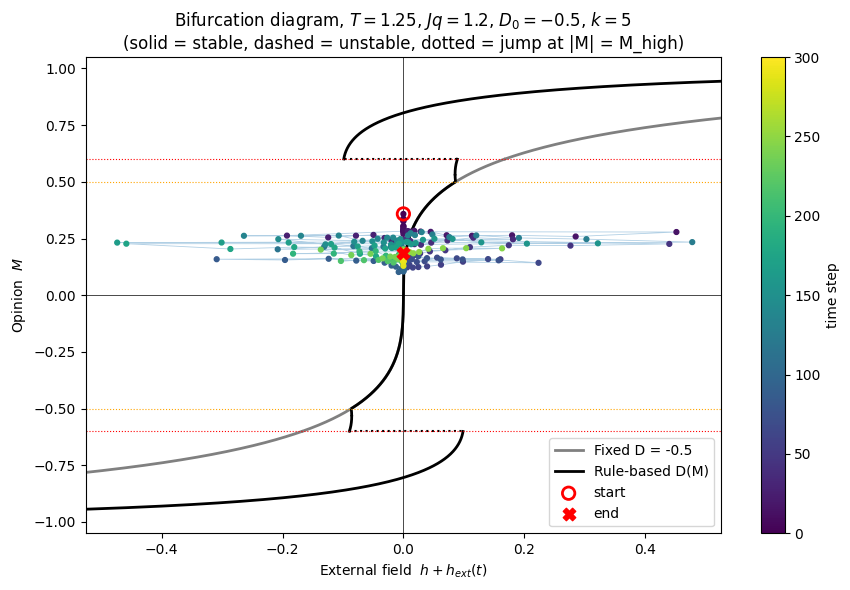

In [64]:
# ============================================================
# BIFURCATION GRAPH: M* vs external field (h + h_ext)
# + the simulated path (h + h_ext(t), M(t)) on top
# Run AFTER the simulation cell (uses Data_M, Data_h_ext)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# ------------------------- SETTINGS -------------------------
T_plot   = Temperature        # temperature used in the simulation
Jq       = J_coupling * q_neighbors   # coupling J*q
Do_plot  = D_initial          # D0
k_plot   = k_sensitivity      # k in the middle band
Mlo_plot = M_low              # low-band threshold (0.5)
Mhi_plot = M_high             # high-band threshold (0.6)

lag        = 0       # shift M by a few steps if it lags behind h (try 1-3)
show_fixed = True    # draw the fixed-D reference curve (grey)
x_range    = None    # e.g. (-0.4, 0.4); None = automatic
# ------------------------------------------------------------


# ---- your D rule (same as in the model) ----
def D_rule(M):
    a = abs(M)
    if a < Mlo_plot:
        return Do_plot
    elif a <= Mhi_plot:
        return Do_plot * (1 + k_plot * (a - Mlo_plot))
    else:
        return -np.exp(abs(Do_plot) + (a - Mhi_plot))

def D_fixed(M):
    return Do_plot


# ---- single-spin response of the restricted (A-B) heat-bath model ----
def M_single(x, D, T):
    # x = beta * h_eff
    c = np.exp(-D / T)
    num = 2*c*np.sinh(x) + 2*c**2*np.sinh(2*x)
    den = 1 + 4*c*np.cosh(x) + 2*c**2*np.cosh(2*x)
    return num / den


# ---- for a given M, find the field h that makes M a steady state ----
# self-consistency: M = M_single(beta*(h + Jq*M), D(M))
# solve for x = beta*h_eff, then h = x*T - Jq*M
def h_of_M(M, D_func):
    D = D_func(M)
    x = brentq(lambda x: M_single(x, D, T_plot) - M, -40, 40)
    return x * T_plot - Jq * M


def branch(D_func):
    # split at the thresholds so the jumps in D are not joined by a line
    edges = [-0.999, -Mhi_plot, -Mlo_plot, Mlo_plot, Mhi_plot, 0.999]
    pieces = []
    for a, b in zip(edges[:-1], edges[1:]):
        Ms = np.linspace(a, b, 400)[1:-1]
        hs = np.array([h_of_M(m, D_func) for m in Ms])
        pieces.append((hs, Ms))
    return pieces


def plot_branch(ax, D_func, color, label):
    first = True
    for hs, Ms in branch(D_func):
        dh = np.gradient(hs, Ms)
        stable = dh > 0                     # stable where h increases with M
        for mask, ls in [(stable, '-'), (~stable, '--')]:
            ax.plot(np.where(mask, hs, np.nan), np.where(mask, Ms, np.nan),
                    ls, color=color, lw=2,
                    label=label if (first and ls == '-') else None)
        first = False
    # dotted horizontal links where D jumps (|M| = M_high)
    for s in [1, -1]:
        Mth = s * Mhi_plot
        h_below = h_of_M(Mth - s*1e-4, D_func)
        h_above = h_of_M(Mth + s*1e-4, D_func)
        ax.plot([h_below, h_above], [Mth, Mth], ':', color=color, lw=1.5)


# ---- print the jump points (useful for the text) ----
h_up   = h_of_M(Mhi_plot - 1e-4, D_rule)   # lower branch ends -> jump UP
h_down = h_of_M(Mhi_plot + 1e-4, D_rule)   # upper branch ends -> drop DOWN
print(f"Jump up   to the locked-in branch at h + h_ext ≈ {h_up:+.3f}")
print(f"Drop down from the locked-in branch at h + h_ext ≈ {h_down:+.3f}")
print(f"Hysteresis width ≈ {h_up - h_down:.3f}")


# ============================ PLOT ============================
fig, ax = plt.subplots(figsize=(9, 6))

if show_fixed:
    plot_branch(ax, D_fixed, 'grey', f'Fixed D = {Do_plot}')
plot_branch(ax, D_rule, 'black', 'Rule-based D(M)')

# ---- simulated path ----
H     = External_field + np.array(h_ext_history, dtype=float)   # total external field h + h_ext
M_sim = np.array(M_history, dtype=float)
n = min(len(H), len(M_sim))
H, M_sim = H[:n], M_sim[:n]
if lag > 0:
    H, M_sim = H[:-lag], M_sim[lag:]
steps = np.arange(len(H))

ax.plot(H, M_sim, '-', color='tab:blue', lw=0.6, alpha=0.35)
sc = ax.scatter(H, M_sim, c=steps, cmap='viridis', s=12, zorder=3)
ax.scatter(H[0], M_sim[0], marker='o', s=80, facecolors='none',
           edgecolors='red', lw=2, zorder=4, label='start')
ax.scatter(H[-1], M_sim[-1], marker='X', s=80, color='red', zorder=4, label='end')
plt.colorbar(sc, ax=ax, label='time step')

# reference lines
ax.axhline(0, color='k', lw=0.5)
ax.axvline(0, color='k', lw=0.5)
for s in [1, -1]:
    ax.axhline(s*Mlo_plot, color='orange', lw=0.8, ls=':')
    ax.axhline(s*Mhi_plot, color='red',    lw=0.8, ls=':')

if x_range is None:
    hx = max(0.4, np.nanmax(np.abs(H)) * 1.1)
    x_range = (-hx, hx)
ax.set_xlim(*x_range)
ax.set_ylim(-1.05, 1.05)
ax.set_xlabel(r'External field  $h + h_{ext}(t)$')
ax.set_ylabel(r'Opinion  $M$')
ax.set_title(rf'Bifurcation diagram, $T={T_plot}$, $Jq={Jq}$, '
             rf'$D_0={Do_plot}$, $k={k_plot}$'
             '\n(solid = stable, dashed = unstable, dotted = jump at |M| = M_high)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

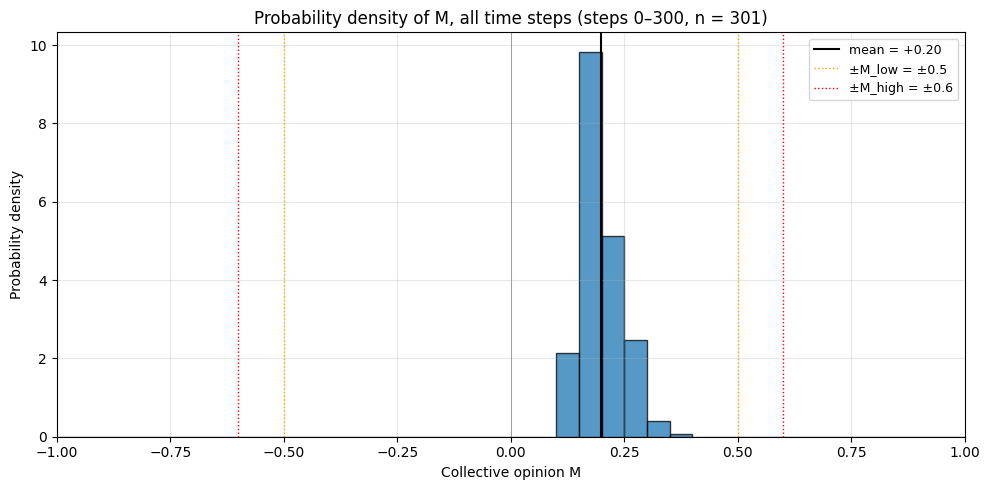

mean = +0.198, std = 0.047, min = +0.10, max = +0.36
time spent with M > +0.6: 0%,  |M| <= 0.6: 100%,  M < -0.6: 0%


In [65]:
# ============================================================
# PROBABILITY DENSITY OF ALL TIME STEPS
# Uses M_history, N_up_history, N_neutral_history, N_down_history from your run
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

# ------------------------- SETTINGS -------------------------
variable   = 'M'        # 'M' = collective opinion, 'p0' = share of neutrals
n_bins     = 40
step_start = 0          # first time step to include (e.g. 20 to skip the start-up)
step_end   = None       # last time step to include (None = until the end)
bar_color  = 'tab:blue'
# ------------------------------------------------------------

N_tot = np.array(N_up_history) + np.array(N_neutral_history) + np.array(N_down_history)
data = {'M':  np.array(M_history, dtype=float),
        'p0': np.array(N_neutral_history) / N_tot}[variable]
last = len(data) - 1 if step_end is None else min(step_end, len(data) - 1)
x_all = data[step_start:last + 1]

x_range = (-1, 1) if variable == 'M' else (0, 1)
bins = np.linspace(*x_range, n_bins + 1)
xlabel = 'Collective opinion M' if variable == 'M' else 'Share of neutrals p(0)'

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(x_all, bins=bins, density=True, color=bar_color, alpha=0.75, edgecolor='k', lw=0.3)
ax.axvline(x_all.mean(), color='k', lw=1.5, label=f'mean = {x_all.mean():+.2f}')

# reference lines: band thresholds
if variable == 'M':
    for s in [1, -1]:
        ax.axvline(s * M_low,  color='orange', ls=':', lw=1,
                   label=f'±M_low = ±{M_low}' if s == 1 else None)
        ax.axvline(s * M_high, color='red',    ls=':', lw=1,
                   label=f'±M_high = ±{M_high}' if s == 1 else None)
    ax.axvline(0, color='grey', lw=0.5)

ax.set_xlim(*x_range)
ax.set_xlabel(xlabel)
ax.set_ylabel('Probability density')
ax.set_title(f'Probability density of {variable}, all time steps '
             f'(steps {step_start}–{last}, n = {len(x_all)})')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---- numbers for the text ----
print(f"mean = {x_all.mean():+.3f}, std = {x_all.std():.3f}, "
      f"min = {x_all.min():+.2f}, max = {x_all.max():+.2f}")
if variable == 'M':
    print(f"time spent with M > +{M_high}: {np.mean(x_all > M_high):.0%},  "
          f"|M| <= {M_high}: {np.mean(np.abs(x_all) <= M_high):.0%},  "
          f"M < -{M_high}: {np.mean(x_all < -M_high):.0%}")

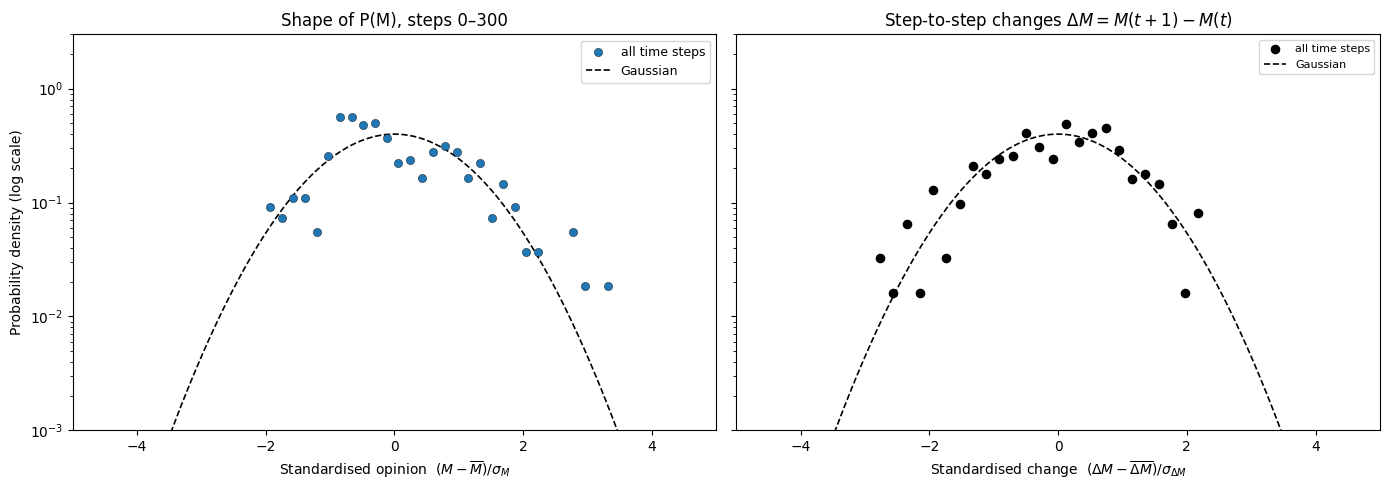

        n    mean    std   skew  ex.kurt
M     301  +0.198  0.047  +0.60    +0.08
dM    300  -0.001  0.010  -0.30    -0.16
largest |dM| = 0.029 between steps 278 and 279 (2.9 std)


In [66]:
# ============================================================
# DISTRIBUTION SHAPE AS SCATTER (log scale) + GAUSSIAN REFERENCE, ALL TIME STEPS
# Left : P(M) of all time steps, standardised  z = (M - mean)/std
# Right: P(dM) of the step-to-step changes dM = M(t+1) - M(t), standardised
#        -> this is where heavy tails (big sudden jumps) show up
# Dashed line = standard normal (Gaussian). Dots above it far from 0 = heavier tails.
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# ------------------------- SETTINGS -------------------------
step_start = 0        # first time step to include (e.g. 20 to skip the start-up)
step_end   = None     # last time step to include (None = until the end)
n_bins_M   = 30
n_bins_dM  = 25
z_lim      = None     # x-range in standard deviations (None = automatic, shows all points)
big_jump   = 3        # mark changes larger than this many standard deviations
# ------------------------------------------------------------

M_all = np.array(M_history, dtype=float)
last  = len(M_all) - 1 if step_end is None else min(step_end, len(M_all) - 1)
M_arr = M_all[step_start:last + 1]

def density_points(x, bins):
    p, edges = np.histogram(x, bins=bins, density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])
    keep = p > 0                      # log scale: drop empty bins
    return centers[keep], p[keep]

def standardise(x):
    return (x - x.mean()) / x.std()

zM = standardise(M_arr)
dM = np.diff(M_arr)                   # dM[i] = M(i+1) - M(i)
z  = standardise(dM)
if z_lim is None:
    z_lim = max(5, np.ceil(max(np.abs(zM).max(), np.abs(z).max())) + 0.5)
zs = np.linspace(-z_lim, z_lim, 400)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# ---- left: shape of P(M), all time steps ----
c, p = density_points(zM, np.linspace(zM.min(), zM.max(), n_bins_M + 1))
axL.scatter(c, p, color='tab:blue', s=35, edgecolors='k', lw=0.3, zorder=3, label='all time steps')
axL.plot(zs, stats.norm.pdf(zs), 'k--', lw=1.2, label='Gaussian')
axL.set_yscale('log'); axL.set_ylim(1e-3, 3); axL.set_xlim(-z_lim, z_lim)
axL.set_xlabel(r'Standardised opinion  $(M - \overline{M})/\sigma_M$')
axL.set_ylabel('Probability density (log scale)')
axL.set_title(f'Shape of P(M), steps {step_start}–{last}')
axL.legend(fontsize=9)

# ---- right: step-to-step changes, all time steps ----
c, p = density_points(z, np.linspace(z.min(), z.max(), n_bins_dM + 1))
axR.scatter(c, p, color='k', s=35, zorder=3, label='all time steps')
axR.plot(zs, stats.norm.pdf(zs), 'k--', lw=1.2, label='Gaussian')
# mark the big jumps and write the time step next to them
big = np.where(np.abs(z) > big_jump)[0]
if len(big):
    axR.scatter(z[big], np.full(len(big), 2e-3), marker='|', s=300, color='tab:red',
                lw=2, label=f'|z| > {big_jump} ({len(big)} steps)')
    for i in big:
        axR.annotate(str(step_start + i + 1), (z[i], 2e-3), textcoords='offset points',
                     xytext=(0, 10), fontsize=7, ha='center', rotation=90)
axR.set_xlim(-z_lim, z_lim)
axR.set_xlabel(r'Standardised change  $(\Delta M - \overline{\Delta M})/\sigma_{\Delta M}$')
axR.set_title(r'Step-to-step changes $\Delta M = M(t+1) - M(t)$')
axR.legend(fontsize=8)

plt.tight_layout(); plt.show()

# ---- numbers for the text ----
# excess kurtosis: 0 = Gaussian, > 0 = heavier tails, < 0 = lighter tails / flatter
print(f"{'':4s} {'n':>4s} {'mean':>7s} {'std':>6s} {'skew':>6s} {'ex.kurt':>8s}")
print(f"M    {len(M_arr):4d} {M_arr.mean():+7.3f} {M_arr.std():6.3f} "
      f"{stats.skew(M_arr):+6.2f} {stats.kurtosis(M_arr):+8.2f}")
print(f"dM   {len(dM):4d} {dM.mean():+7.3f} {dM.std():6.3f} "
      f"{stats.skew(dM):+6.2f} {stats.kurtosis(dM):+8.2f}")
k = np.argmax(np.abs(dM))
print(f"largest |dM| = {abs(dM[k]):.3f} between steps {step_start + k} and {step_start + k + 1} "
      f"({abs(z[k]):.1f} std)")
if len(big):
    print(f"steps with |z| > {big_jump}: {(step_start + big + 1).tolist()}")

__COMPARISON__

In [67]:
# ============================================================
# RUN ALL T-VARIATIONS AND STORE THE RESULTS
# (rule-based D in every run, only the temperature changes)
# ============================================================
import numpy as np

# events file used for this comparison (generate it first with your generator cell)
events_used = np.load("raw_external_field58.npy").tolist()

Tc = 1.249        # critical temperature for Jq = 1.2, D0 = -0.5
conditions = {
    'T = 0.9 Tc': dict(T=0.9*Tc),
    'T = Tc':     dict(T=Tc),
    'T = 1.1 Tc': dict(T=1.1*Tc),
}

all_results = {}
for name, c in conditions.items():
    print(f"--- running {name} (T = {c['T']:.3f}) ---")
    np.random.seed(42)                       # SAME seed for every condition -> fair comparison
    res = simulate_open_population(N_up_initial, N_down_initial, N_o,
                                   c['T'],                     # <- the temperature of this condition
                                   External_field, J_coupling, q_neighbors,
                                   D_initial, k_sensitivity,   # <- rule-based D as in your parameter cell
                                   r_growth, Time_steps, events_used,
                                   M_low=M_low, M_high=M_high, dt=1.0)
    (N_up_h, N_down_h, N_0_h, M_h, N_tot_h, h_ext_h, h_eff_h, D_h, _, _, h_felt_h) = res
    all_results[name] = dict(M=np.array(M_h), N_up=np.array(N_up_h), N_down=np.array(N_down_h),
                             N_0=np.array(N_0_h), D=np.array(D_h),
                             h_ext=np.array(h_ext_h), h_felt=np.array(h_felt_h))

# save to a file so you don't lose the runs if Colab disconnects
np.save("results_T_variation.npy", all_results, allow_pickle=True)

--- running T = 0.9 Tc (T = 1.124) ---
MCS 10/300 selesai | N = 5051
MCS 20/300 selesai | N = 5051
MCS 30/300 selesai | N = 5051
MCS 40/300 selesai | N = 5051
MCS 50/300 selesai | N = 5051
MCS 60/300 selesai | N = 5051
MCS 70/300 selesai | N = 5051
MCS 80/300 selesai | N = 5051
MCS 90/300 selesai | N = 5051
MCS 100/300 selesai | N = 5051
MCS 110/300 selesai | N = 5051
MCS 120/300 selesai | N = 5051
MCS 130/300 selesai | N = 5051
MCS 140/300 selesai | N = 5051
MCS 150/300 selesai | N = 5051
MCS 160/300 selesai | N = 5051
MCS 170/300 selesai | N = 5051
MCS 180/300 selesai | N = 5051
MCS 190/300 selesai | N = 5051
MCS 200/300 selesai | N = 5051
MCS 210/300 selesai | N = 5051
MCS 220/300 selesai | N = 5051
MCS 230/300 selesai | N = 5051
MCS 240/300 selesai | N = 5051
MCS 250/300 selesai | N = 5051
MCS 260/300 selesai | N = 5051
MCS 270/300 selesai | N = 5051
MCS 280/300 selesai | N = 5051
MCS 290/300 selesai | N = 5051
MCS 300/300 selesai | N = 5051
--- running T = Tc (T = 1.249) ---
MCS 1

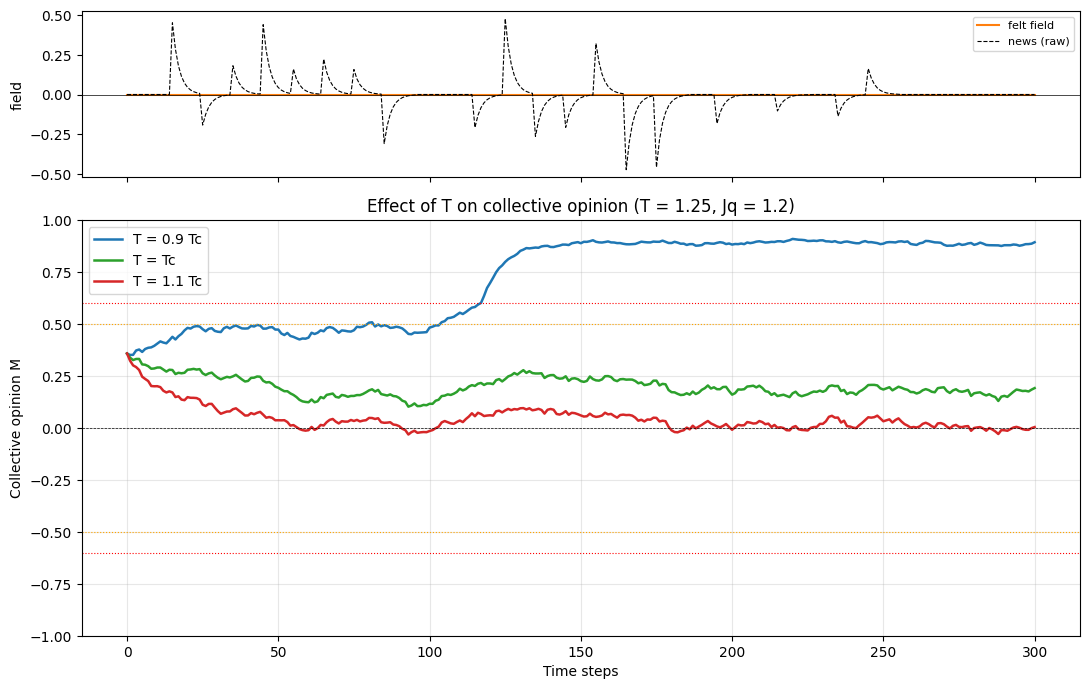

In [68]:
# ============================================================
# PLOT: M(t) for all T-variations in one graph
# ============================================================
import numpy as np
import matplotlib.pyplot as plt

all_results = np.load("results_T_variation.npy", allow_pickle=True).item()   # only needed after a restart

colors = {'T = 0.9 Tc': 'tab:blue', 'T = Tc': 'tab:green', 'T = 1.1 Tc': 'tab:red'}

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                               gridspec_kw={'height_ratios': [1, 2.5]})

# top: the felt field (the same for every condition)
first = next(iter(all_results.values()))
ax0.plot(first['h_felt'], color='tab:orange', lw=1.5, label='felt field')
ax0.plot(first['h_ext'], 'k--', lw=0.8, label='news (raw)')
ax0.axhline(0, color='k', lw=0.5); ax0.set_ylabel('field'); ax0.legend(fontsize=8)

# bottom: M(t) of every condition
for name, r in all_results.items():
    ax1.plot(r['M'], color=colors.get(name), lw=1.8, label=name)
for s in [1, -1]:
    ax1.axhline(s * 0.5, color='orange', ls=':', lw=0.8)
    ax1.axhline(s * 0.6, color='red', ls=':', lw=0.8)
ax1.axhline(0, color='k', ls='--', lw=0.5)
ax1.set_ylim(-1, 1); ax1.set_xlabel('Time steps'); ax1.set_ylabel('Collective opinion M')
ax1.set_title(f'Effect of T on collective opinion (T = {Temperature}, Jq = {J_coupling*q_neighbors})')
ax1.legend(); ax1.grid(alpha=0.3)
plt.tight_layout(); plt.show()

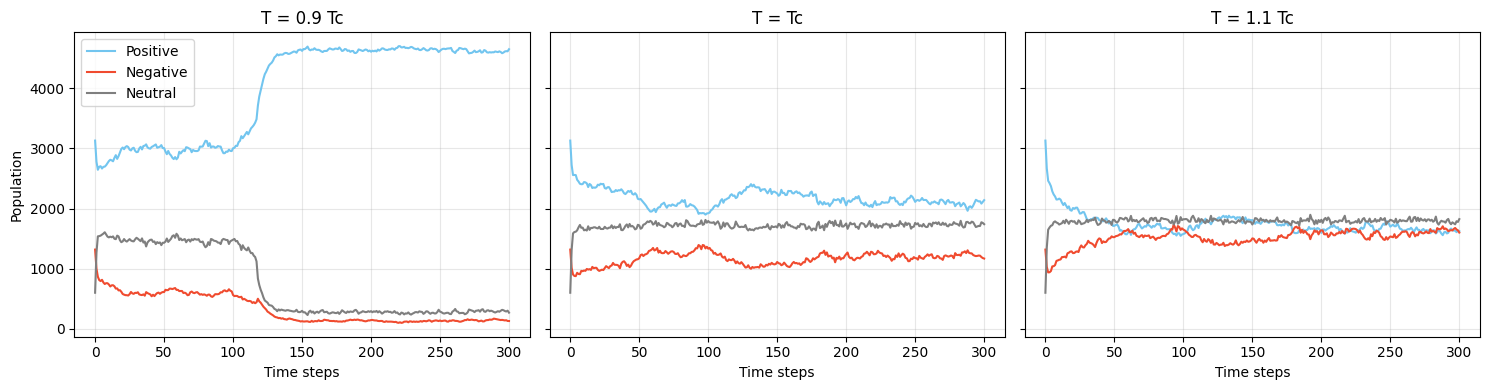

In [69]:
fig, axes = plt.subplots(1, len(all_results), figsize=(5 * len(all_results), 4), sharey=True)
for ax, (name, r) in zip(axes, all_results.items()):
    ax.plot(r['N_up'], color="#72C5EF", label='Positive')
    ax.plot(r['N_down'], color="#F04B2F", label='Negative')
    ax.plot(r['N_0'], color="#7F7F7F", label='Neutral')
    ax.set_title(name); ax.set_xlabel('Time steps'); ax.grid(alpha=0.3)
axes[0].set_ylabel('Population'); axes[0].legend()
plt.tight_layout(); plt.show()

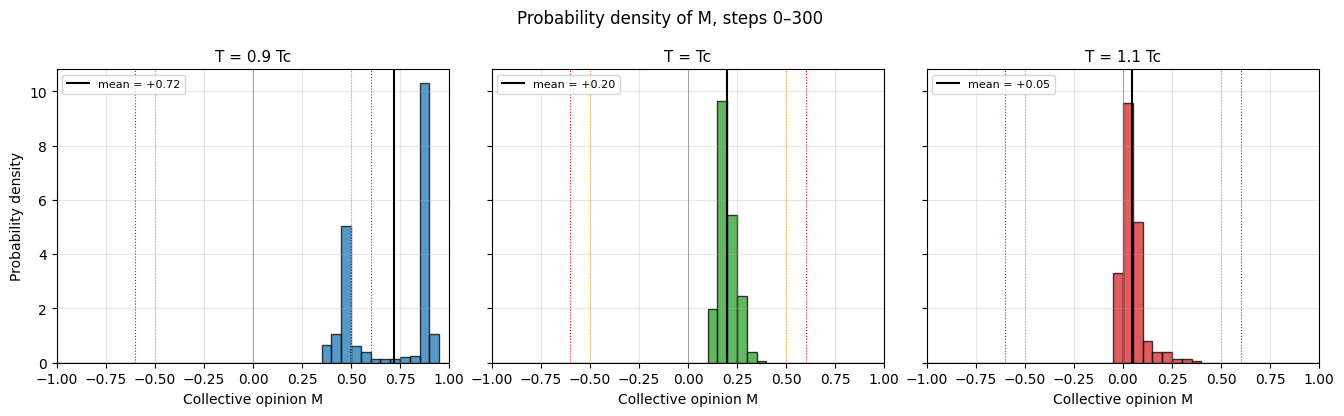

condition           mean    std   kurt |  M>+0.6 |M|<=0.6  M<-0.6
T = 0.9 Tc        +0.720  0.204  -1.67 |     61%      39%      0%
T = Tc            +0.199  0.047  +0.10 |      0%     100%      0%
T = 1.1 Tc        +0.046  0.060  +6.40 |      0%     100%      0%


In [70]:
# ============================================================
# COMPARE PROBABILITY DISTRIBUTIONS OF M BETWEEN CONDITIONS
# One histogram panel per condition (side by side, same axes)
# Works for any saved experiment file (D-, T- or event-variation)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# ------------------------- SETTINGS -------------------------
results_file = "results_T_variation.npy"   # which experiment to show
step_start   = 0          # skip the start-up if you want (e.g. 20)
n_bins       = 40
colors = {'T = 0.9 Tc': 'tab:blue', 'T = Tc': 'tab:green', 'T = 1.1 Tc': 'tab:red'}  # None -> default colours
# ------------------------------------------------------------

all_results = np.load(results_file, allow_pickle=True).item()
names = list(all_results.keys())
bins = np.linspace(-1, 1, n_bins + 1)
default_cols = plt.rcParams['axes.prop_cycle'].by_key()['color']

fig, axes = plt.subplots(1, len(names), figsize=(4.5 * len(names), 4.2), sharex=True, sharey=True)
axes = np.atleast_1d(axes)

for j, (ax, name) in enumerate(zip(axes, names)):
    M = all_results[name]['M'][step_start:]
    col = colors.get(name) if colors else default_cols[j % len(default_cols)]

    ax.hist(M, bins=bins, density=True, color=col, alpha=0.75, edgecolor='k', lw=0.3)
    ax.axvline(M.mean(), color='k', lw=1.5, label=f'mean = {M.mean():+.2f}')

    # band thresholds
    for s in [1, -1]:
        ax.axvline(s * 0.5, color='orange', ls=':', lw=0.8)
        ax.axvline(s * 0.6, color='red', ls=':', lw=0.8)
    ax.axvline(0, color='grey', lw=0.5)

    ax.set_xlim(-1, 1)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel('Collective opinion M')
    ax.legend(fontsize=8, loc='upper left')
    ax.grid(alpha=0.3)

axes[0].set_ylabel('Probability density')
n_steps = len(all_results[names[0]]['M']) - 1
fig.suptitle(f'Probability density of M, steps {step_start}–{n_steps}')
plt.tight_layout(); plt.show()

# ---- numbers for the text ----
print(f"{'condition':16s} {'mean':>7s} {'std':>6s} {'kurt':>6s} | {'M>+0.6':>7s} {'|M|<=0.6':>8s} {'M<-0.6':>7s}")
for name in names:
    M = all_results[name]['M'][step_start:]
    print(f"{name:16s} {M.mean():+7.3f} {M.std():6.3f} {stats.kurtosis(M):+6.2f} | "
          f"{np.mean(M > 0.6):7.0%} {np.mean(np.abs(M) <= 0.6):8.0%} {np.mean(M < -0.6):7.0%}")

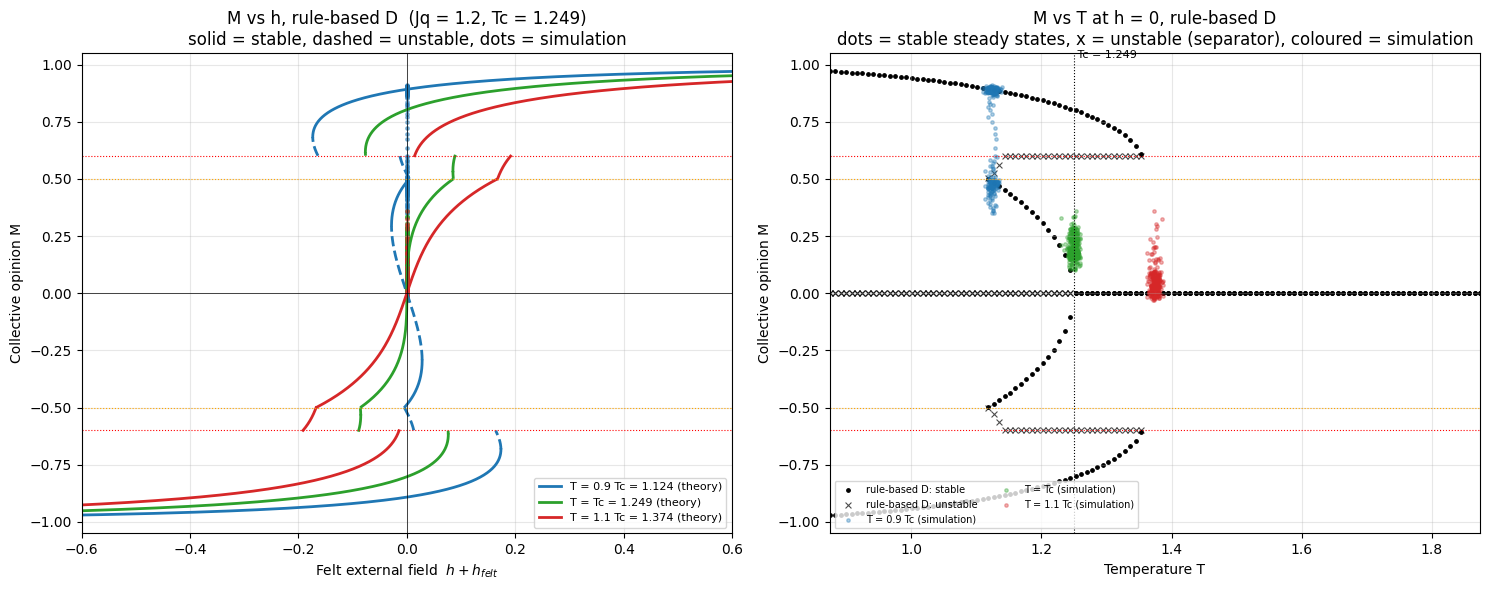

T = 0.9 Tc (T = 1.124): stable M = [np.float64(0.49), np.float64(0.89)], unstable (separator) M = [0.0, np.float64(0.52)]  (and their negatives)
T = Tc (T = 1.249): stable M = [0.0, np.float64(0.8)], unstable (separator) M = [np.float64(0.6)]  (and their negatives)
T = 1.1 Tc (T = 1.374): stable M = [0.0], unstable (separator) M = []  (and their negatives)


In [71]:
# ============================================================
# BIFURCATION COMPARISON FOR THE T-VARIATION (rule-based D in every run)
# Left : M vs h  - theory branches for each temperature + simulated paths
# Right: M vs T  - steady states at h = 0 as a function of T
#                  (fixed D = D0 as reference, and the rule-based D) + simulated (T, M) points
# Uses: compute_D, the parameters (J_coupling, q_neighbors, D_initial, k_sensitivity,
#       M_low, M_high, External_field) and the saved results file
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# ------------------------- SETTINGS -------------------------
results_file = "results_T_variation.npy"
Jq = J_coupling * q_neighbors

# critical temperature of the model (set by D0 at M = 0)
def critical_T(Jq, D0):
    T = 1.0
    for _ in range(2000):
        c = np.exp(-D0 / T)
        T = 2 * Jq * c * (1 + 2*c) / (1 + 4*c + 2*c**2)
    return T
Tc = critical_T(Jq, D_initial)

# temperature of every condition -> must match the names in the run cell
T_settings = {
    'T = 0.9 Tc': 0.9 * Tc,
    'T = Tc':     1.0 * Tc,
    'T = 1.1 Tc': 1.1 * Tc,
}
colors = {'T = 0.9 Tc': 'tab:blue', 'T = Tc': 'tab:green', 'T = 1.1 Tc': 'tab:red'}
show_paths = True           # draw the simulated runs on top of the theory
h_range    = (-0.6, 0.6)    # x-range of the M vs h panel
T_range    = (0.7 * Tc, 1.5 * Tc)   # x-range of the M vs T panel
# ------------------------------------------------------------

all_results = np.load(results_file, allow_pickle=True).item()
D_rule  = lambda M: compute_D(M, D_initial, k_sensitivity, M_low, M_high)

# single-spin response of the restricted (A-B) heat-bath model, x = h_eff / T
def M_single(x, D, T):
    c = np.exp(-D / T)
    return (2*c*np.sinh(x) + 2*c**2*np.sinh(2*x)) / (1 + 4*c*np.cosh(x) + 2*c**2*np.cosh(2*x))

# ---------- M vs h: for every M, the field h that makes M a steady state at temperature T ----------
def h_of_M(M, D, T):
    x = brentq(lambda x: M_single(x, D, T) - M, -40, 40)
    return x * T - Jq * M

def plot_h_branches(ax, D_func, T, color, label):
    edges = [-0.999, -M_high, -M_low, M_low, M_high, 0.999]     # split where the rule jumps
    first = True
    for a, b in zip(edges[:-1], edges[1:]):
        Ms = np.linspace(a, b, 300)[1:-1]
        hs = np.array([h_of_M(m, D_func(m), T) for m in Ms])
        stable = np.gradient(hs, Ms) > 0                          # stable where h rises with M
        for mask, ls in [(stable, '-'), (~stable, '--')]:
            ax.plot(np.where(mask, hs, np.nan), np.where(mask, Ms, np.nan), ls, color=color, lw=2,
                    label=label if (first and ls == '-') else None)
        first = False

# ---------- M vs T: steady states at h = 0 ----------
def steady_states(D_func, T, n=3000):
    # roots of g(M) = M_single(Jq*M/T, D(M), T) - M for M > 0
    Ms = np.linspace(1e-3, 0.999, n)
    g = np.array([M_single(Jq * m / T, D_func(m), T) - m for m in Ms])
    stable, unstable = [], []
    for i in range(n - 1):
        if g[i] > 0 >= g[i+1]:   stable.append(Ms[i])     # pushed back from both sides
        elif g[i] < 0 <= g[i+1]: unstable.append(Ms[i])   # pushed away (separator)
    # M = 0 is always a steady state: stable if g < 0 just above 0
    (stable if g[0] < 0 else unstable).append(0.0)
    return stable, unstable

fig, (axL, axR) = plt.subplots(1, 2, figsize=(15, 6))

# ======================= LEFT: M vs h =======================
for name, T in T_settings.items():
    plot_h_branches(axL, D_rule, T, colors[name], f'{name} = {T:.3f} (theory)')
    if show_paths and name in all_results:
        r = all_results[name]
        H = External_field + np.asarray(r['h_felt'], dtype=float)
        axL.plot(H, r['M'], '-', color=colors[name], lw=0.7, alpha=0.45)
        axL.scatter(H, r['M'], color=colors[name], s=6, alpha=0.5)
for s in [1, -1]:
    axL.axhline(s * M_low, color='orange', ls=':', lw=0.8)
    axL.axhline(s * M_high, color='red', ls=':', lw=0.8)
axL.axhline(0, color='k', lw=0.5); axL.axvline(0, color='k', lw=0.5)
axL.set_xlim(*h_range); axL.set_ylim(-1.05, 1.05)
axL.set_xlabel(r'Felt external field  $h + h_{felt}$'); axL.set_ylabel('Collective opinion M')
axL.set_title(f'M vs h, rule-based D  (Jq = {Jq}, Tc = {Tc:.3f})\nsolid = stable, dashed = unstable, dots = simulation')
axL.legend(fontsize=8, loc='lower right'); axL.grid(alpha=0.3)

# ======================= RIGHT: M vs T =======================
Ts = np.linspace(*T_range, 120)
for D_func, col, lab in [(D_rule, 'k', 'rule-based D')]:
    first_s = first_u = True
    for T in Ts:
        st, un = steady_states(D_func, T)
        for m in st:
            axR.scatter([T, T], [m, -m], color=col, s=6, label=f'{lab}: stable' if first_s else None); first_s = False
        for m in un:
            axR.scatter([T, T], [m, -m], color=col, s=18, marker='x', lw=0.8, alpha=0.7,
                        label=f'{lab}: unstable' if first_u else None); first_u = False
axR.axvline(Tc, color='k', ls=':', lw=0.8)
axR.text(Tc, 1.02, f' Tc = {Tc:.3f}', fontsize=8, va='bottom')

# simulated runs: all M values of a run plotted at its temperature (small jitter so the points do not overlap)
if show_paths:
    rng = np.random.default_rng(0)
    for name, T in T_settings.items():
        if name in all_results:
            M = np.asarray(all_results[name]['M'], dtype=float)
            axR.scatter(T + rng.normal(0, 0.004 * Tc, len(M)), M, color=colors[name], s=6, alpha=0.35,
                        label=f'{name} (simulation)')

for s in [1, -1]:
    axR.axhline(s * M_low, color='orange', ls=':', lw=0.8)
    axR.axhline(s * M_high, color='red', ls=':', lw=0.8)
axR.set_xlim(*T_range); axR.set_ylim(-1.05, 1.05)
axR.set_xlabel('Temperature T'); axR.set_ylabel('Collective opinion M')
axR.set_title('M vs T at h = 0, rule-based D\ndots = stable steady states, x = unstable (separator), coloured = simulation')
axR.legend(fontsize=7, loc='lower left', ncol=2); axR.grid(alpha=0.3)

plt.tight_layout(); plt.show()

# ---- numbers for the text: steady states of the rule-based model at each temperature ----
for name, T in T_settings.items():
    st, un = steady_states(D_rule, T)
    print(f"{name} (T = {T:.3f}): stable M = {[round(m, 2) for m in sorted(st)]}, "
          f"unstable (separator) M = {[round(m, 2) for m in sorted(un)]}  (and their negatives)")